# Imports & Load Feedback Dataset

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv("customer_feedback.csv")
df.head()

,feedback_id,customer_name,feedback_text
0,1,Customer_1,Bought a Smart Watch while visiting Mumbai. Pe...
1,2,Customer_2,Received the USB-C Hub yesterday in Pune. Pack...
2,3,Customer_3,Really impressed with the Laptop Stand. Fast s...
3,4,Customer_4,Bought a Smart Watch while visiting Goa. Perfo...
4,5,Customer_5,I absolutely LOVE the Wireless Headphones I or...


# Cleaning and Normalizing the text

In [2]:
def preprocess_text(text) -> str:
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_feedback'] = df['feedback_text'].apply(preprocess_text)
df.head()

,feedback_id,customer_name,feedback_text,cleaned_feedback
0,1,Customer_1,Bought a Smart Watch while visiting Mumbai. Pe...,bought a smart watch while visiting mumbai per...
1,2,Customer_2,Received the USB-C Hub yesterday in Pune. Pack...,received the usbc hub yesterday in pune packag...
2,3,Customer_3,Really impressed with the Laptop Stand. Fast s...,really impressed with the laptop stand fast sh...
3,4,Customer_4,Bought a Smart Watch while visiting Goa. Perfo...,bought a smart watch while visiting goa perfor...
4,5,Customer_5,I absolutely LOVE the Wireless Headphones I or...,i absolutely love the wireless headphones i or...


# Small labeled training examples for our ML classifier

In [4]:
train_texts = [
    "love amazing sound build quality",
    "best purchase works great arrived early",
    "fantastic superb performance great value",
    "impressed fast shipping works flawlessly",
    "terrible experience stopped working",
    "disappointed feels cheap overheats returned",
    "awful quality broken box delivered",
    "poor battery life unhelpful support waste money",
    "arrived time okay basic job",
    "standard delivery nothing extraordinary works expected",
    "performance average fine price",
    "received yesterday packaging decent setup normal"
]

train_labels = [
    "Positive", "Positive", "Positive", "Positive",
    "Negative", "Negative", "Negative", "Negative",
    "Neutral", "Neutral", "Neutral", "Neutral"
]
vectorizer = TfidfVectorizer(stop_words="english")
X_train = vectorizer.fit_transform(train_texts)

model = MultinomialNB()
model.fit(X_train, train_labels)

X_test = vectorizer.transform(df["cleaned_feedback"])
df["sentiment"] = model.predict(X_test)

df[["feedback_text", "sentiment"]].head(10)

,feedback_text,sentiment
0,Bought a Smart Watch while visiting Mumbai. Pe...,Neutral
1,Received the USB-C Hub yesterday in Pune. Pack...,Neutral
2,Really impressed with the Laptop Stand. Fast s...,Positive
3,Bought a Smart Watch while visiting Goa. Perfo...,Neutral
4,I absolutely LOVE the Wireless Headphones I or...,Positive
5,Really impressed with the Mechanical Keyboard....,Positive
6,Standard delivery in Ahmedabad for the Wireles...,Neutral
7,Really impressed with the Bluetooth Speaker. F...,Positive
8,Poor battery life on the USB-C Hub and unhelpf...,Negative
9,Fantastic Bluetooth Speaker! Superb performanc...,Positive


# Extract City Names

In [5]:
cities = ["Mumbai", "Delhi", "Bangalore", "Pune", "Chennai", "Hyderabad", "Goa", "Kolkata", "Ahmedabad"]

def get_city(text):
    for city in cities:
        if city.lower() in text.lower():
            return city
    return "Unknown"

df["city"] = df["feedback_text"].apply(get_city)
df[["feedback_text", "city", "sentiment"]].head(10)

,feedback_text,city,sentiment
0,Bought a Smart Watch while visiting Mumbai. Pe...,Mumbai,Neutral
1,Received the USB-C Hub yesterday in Pune. Pack...,Pune,Neutral
2,Really impressed with the Laptop Stand. Fast s...,Delhi,Positive
3,Bought a Smart Watch while visiting Goa. Perfo...,Goa,Neutral
4,I absolutely LOVE the Wireless Headphones I or...,Delhi,Positive
5,Really impressed with the Mechanical Keyboard....,Ahmedabad,Positive
6,Standard delivery in Ahmedabad for the Wireles...,Ahmedabad,Neutral
7,Really impressed with the Bluetooth Speaker. F...,Pune,Positive
8,Poor battery life on the USB-C Hub and unhelpf...,Mumbai,Negative
9,Fantastic Bluetooth Speaker! Superb performanc...,Hyderabad,Positive


# Sentiment Category Distribution

In [6]:
print("Sentiment Counts:")
print(df["sentiment"].value_counts())

print("\nSentiment Percentages:")
print((df["sentiment"].value_counts(normalize=True) * 100).round(1))

Sentiment Counts:
sentiment
Neutral     24
Positive    18
Negative    18
Name: count, dtype: int64

Sentiment Percentages:
sentiment
Neutral     40.0
Positive    30.0
Negative    30.0
Name: proportion, dtype: float64


# Two Visualizations

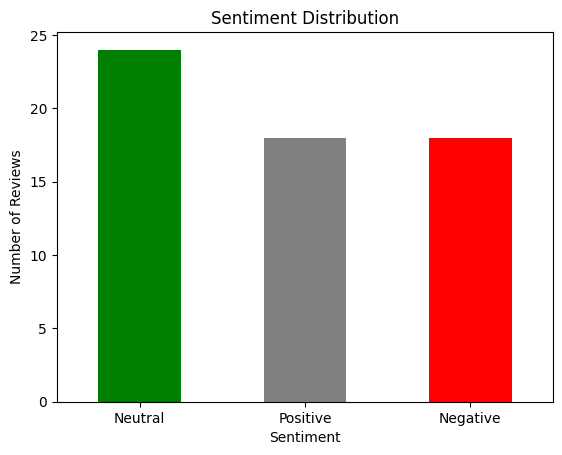

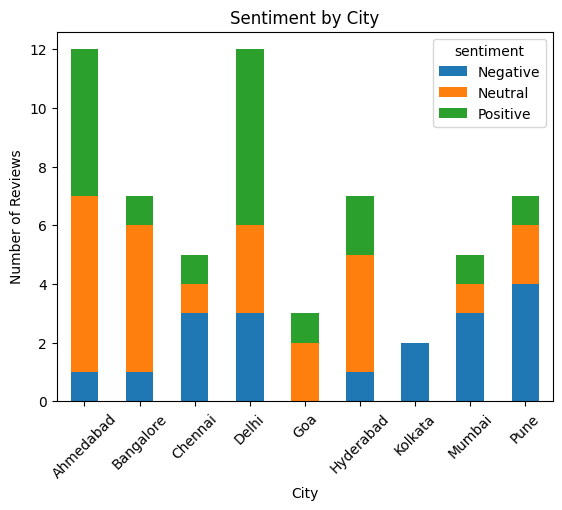

In [7]:
df["sentiment"].value_counts().plot(kind="bar", color=["green", "gray", "red"], rot=0)
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

city_chart = pd.crosstab(df["city"], df["sentiment"])
city_chart.plot(kind="bar", stacked=True, rot=45)
plt.title("Sentiment by City")
plt.xlabel("City")
plt.ylabel("Number of Reviews")
plt.show()